In [2]:
from src.data_loader import load_data

# Load the dataset through our pipeline.
df = load_data()

print("DATA PIPELINE TEST")
print("==================")

print("Dataset shape:", df.shape)
print("Unique vehicles:", df["vehicle_hash"].nunique())
print("Detection events:", df["detection_id"].nunique())

print("\nProcessing status:")
print(df["processing_status"].value_counts())

print("\nCamera distribution:")
print(df["camera_id"].value_counts())

print("\nTimestamp information:")
print(df["timestamp"].dtype)
print(df["timestamp"].min())
print(df["timestamp"].max())

print("\nSample records:")
display(df.head())


DATA PIPELINE TEST
Dataset shape: (8500, 23)
Unique vehicles: 2979
Detection events: 8500

Processing status:
processing_status
success    7562
partial     670
failed      268
Name: count, dtype: int64

Camera distribution:
camera_id
CAM_001    2378
CAM_002    2019
CAM_004    1739
CAM_003    1532
CAM_005     832
Name: count, dtype: int64

Timestamp information:
datetime64[us, Africa/Lagos]
2026-10-15 00:18:28+01:00
2026-11-13 23:55:57+01:00

Sample records:


,detection_id,timestamp,camera_id,location,plate_number,registration_state,registration_lga,plate_type,car_brand,vehicle_category,...,image_path,vehicle_hash,processing_status,data_source,date,hour,day_name,day_of_week,day_type,year_month
0,DET_005555,2026-10-15 00:18:28+01:00,CAM_005,"Wuse, FCT",KJA-568-XA,Lagos,Ikeja,Private,Toyota,Pickup,...,NaN,VH_00914,success,synthetic,2026-10-15,0,Thursday,3,Weekday,2026-10
1,DET_002415,2026-10-15 00:37:56+01:00,CAM_002,"Lekki, Lagos",ILR-907-VD,Kwara,Ilorin,Private,Nissan,SUV,...,NaN,VH_02919,success,synthetic,2026-10-15,0,Thursday,3,Weekday,2026-10
2,DET_004387,2026-10-15 00:52:18+01:00,CAM_005,"Wuse, FCT",KJA-969-ME,Lagos,Ikeja,Private,Toyota,Sedan,...,NaN,VH_01028,success,synthetic,2026-10-15,0,Thursday,3,Weekday,2026-10
3,DET_005619,2026-10-15 01:26:55+01:00,CAM_004,"Victoria Island, Lagos",PHC-443-WZ,NaN,NaN,Private,Peugeot,SUV,...,NaN,VH_00639,partial,synthetic,2026-10-15,1,Thursday,3,Weekday,2026-10
4,DET_006889,2026-10-15 01:31:36+01:00,CAM_002,"Lekki, Lagos",AKU-886-HY,NaN,NaN,Private,Honda,SUV,...,NaN,VH_01534,partial,synthetic,2026-10-15,1,Thursday,3,Weekday,2026-10


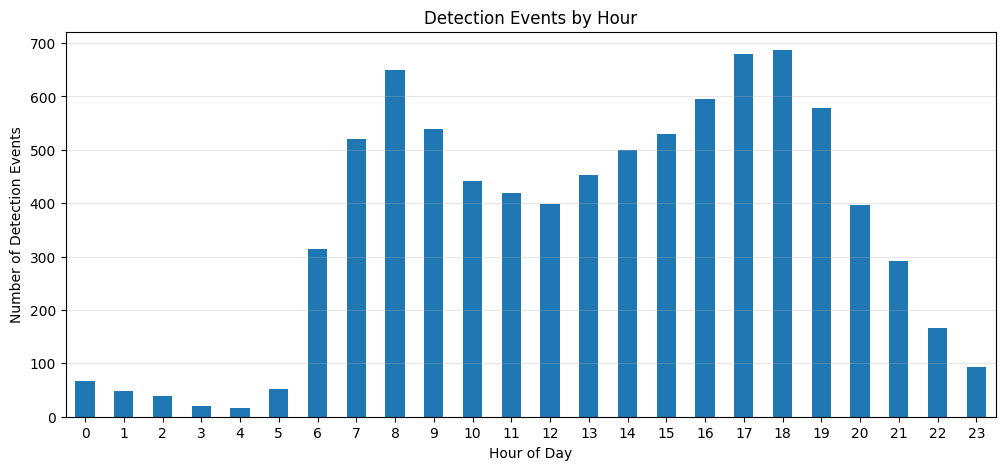

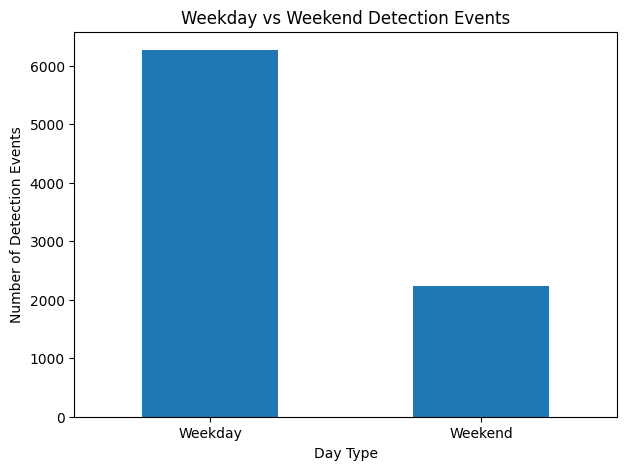

In [3]:
import matplotlib.pyplot as plt

# Hourly detection distribution
hourly_counts = df.groupby("hour").size()

plt.figure(figsize=(12, 5))
hourly_counts.plot(kind="bar")

plt.title("Detection Events by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Detection Events")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Weekday vs weekend
day_counts = df.groupby("day_type").size()

plt.figure(figsize=(7, 5))
day_counts.plot(kind="bar")

plt.title("Weekday vs Weekend Detection Events")
plt.xlabel("Day Type")
plt.ylabel("Number of Detection Events")
plt.xticks(rotation=0)
plt.show()


In [4]:
day_counts

day_type
Weekday    6269
Weekend    2231
dtype: int64

Inspecting Registration LGA

In [5]:
# Inspect the actual registration LGA values
print("UNIQUE REGISTRATION LGAs:")
print(sorted(df["registration_lga"].dropna().unique()))

print("\nREGISTRATION STATE VALUES:")
print(sorted(df["registration_state"].dropna().unique()))

print("\nSTATE-LGA COMBINATIONS:")
display(
    df.groupby(
        ["registration_state", "registration_lga"],
        dropna=False
    ).size().reset_index(name="detection_count")
    .sort_values("detection_count", ascending=False)
)

UNIQUE REGISTRATION LGAs:
['Abeokuta', 'Abuja Municipal', 'Akure', 'Badagry', 'Benin City', 'Enugu', 'Epe', 'Gwagwalada', 'Ibadan', 'Ikeja', 'Ilorin', 'Jos', 'Kano Municipal', 'Lagos Island', 'Port Harcourt']

REGISTRATION STATE VALUES:
['Edo', 'Enugu', 'FCT', 'Kano', 'Kwara', 'Lagos', 'Ogun', 'Ondo', 'Oyo', 'Plateau', 'Rivers']

STATE-LGA COMBINATIONS:


,registration_state,registration_lga,detection_count
8,Lagos,Ikeja,1011
15,NaN,NaN,722
12,Oyo,Ibadan,565
13,Plateau,Jos,523
4,Kano,Kano Municipal,515
6,Lagos,Badagry,508
2,FCT,Abuja Municipal,504
0,Edo,Benin City,491
10,Ogun,Abeokuta,491
3,FCT,Gwagwalada,478


In [6]:
# Correct illustrative city-level labels in the synthetic dataset

admin_mapping = {
    "Abeokuta": ("Abeokuta South", "LGA"),
    "Ibadan": ("Ibadan North", "LGA"),
    "Jos": ("Jos North", "LGA"),
    "Benin City": ("Oredo", "LGA"),
    "Enugu": ("Enugu North", "LGA"),
    "Akure": ("Akure South", "LGA"),
    "Ilorin": ("Ilorin West", "LGA"),
    "Port Harcourt": ("Port Harcourt City", "LGA"),
    "Abuja Municipal": ("Abuja Municipal", "Area Council"),
    "Gwagwalada": ("Gwagwalada", "Area Council"),
    "Kano Municipal": ("Kano Municipal", "LGA"),
    "Ikeja": ("Ikeja", "LGA"),
    "Badagry": ("Badagry", "LGA"),
    "Epe": ("Epe", "LGA"),
    "Lagos Island": ("Lagos Island", "LGA")
}

# Create the new administrative area column
df["registration_admin_area"] = (
    df["registration_lga"]
    .map(lambda x: admin_mapping.get(x, (None, None))[0])
)

# Create the administrative type column
df["registration_admin_type"] = (
    df["registration_lga"]
    .map(lambda x: admin_mapping.get(x, (None, None))[1])
)

# Preserve missing administrative information
missing_mask = df["registration_lga"].isna()

df.loc[missing_mask, "registration_admin_area"] = None
df.loc[missing_mask, "registration_admin_type"] = None

# Inspect the result
display(
    df.groupby(
        ["registration_state",
         "registration_admin_area",
         "registration_admin_type"],
        dropna=False
    ).size().reset_index(name="detection_count")
)

,registration_state,registration_admin_area,registration_admin_type,detection_count
0,Edo,Oredo,LGA,491
1,Enugu,Enugu North,LGA,478
2,FCT,Abuja Municipal,Area Council,504
3,FCT,Gwagwalada,Area Council,478
4,Kano,Kano Municipal,LGA,515
5,Kwara,Ilorin West,LGA,447
6,Lagos,Badagry,LGA,508
7,Lagos,Epe,LGA,477
8,Lagos,Ikeja,LGA,1011
9,Lagos,Lagos Island,LGA,430


In [8]:
from src.data_loader import load_data

df = load_data()

print("DATASET SHAPE:", df.shape)

print("\nNEW ADMINISTRATIVE COLUMNS:")
display(
    df[
        [
            "registration_state",
            "registration_admin_area",
            "registration_admin_type"
        ]
    ].drop_duplicates().sort_values(
        ["registration_state", "registration_admin_area"],
        na_position="last"
    )
)

print("\nADMINISTRATIVE TYPE COUNTS:")
print(df["registration_admin_type"].value_counts(dropna=False))

DATASET SHAPE: (8500, 23)

NEW ADMINISTRATIVE COLUMNS:


KeyError: "['registration_admin_area', 'registration_admin_type'] not in index"